In [1]:
import os
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use("ggplot")
%matplotlib inline

from tqdm import tqdm_notebook, tnrange
from itertools import chain
from skimage.io import imread, imshow, concatenate_images
from skimage.transform import resize
from skimage.morphology import label
from sklearn.model_selection import train_test_split

import tensorflow as tf

from keras.models import Model, load_model
from keras.layers import Input, BatchNormalization, Activation, Dense, Dropout
from keras.layers.core import Lambda, RepeatVector, Reshape
from keras.layers.convolutional import Conv2D, Conv2DTranspose
from keras.layers.pooling import MaxPooling2D, GlobalMaxPool2D
from keras.layers.merge import concatenate, add
from keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from keras.optimizers import Adam
from keras.preprocessing.image import ImageDataGenerator, array_to_img, img_to_array, load_img

# New Section

In [2]:
im_width = 64
im_height = 64
border = 5

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [11]:
ids = next(os.walk("/content/drive/My Drive/docu_detect/docu500"))[2] # list of names all images in the given path
print("No. of images = ", len(ids))

No. of images =  500


In [12]:
X = np.zeros((len(ids), im_height, im_width, 1), dtype=np.float32)
y = np.zeros((len(ids), im_height, im_width, 1), dtype=np.float32)

In [13]:
# tqdm is used to display the progress bar
for n, id_ in tqdm_notebook(enumerate(ids), total=len(ids)):
    # Load images
    img = load_img("/content/drive/My Drive/docu_detect/docu500/"+id_, grayscale=True)
    x_img = img_to_array(img)
    #x_img = resize(x_img, (64, 64, 1), mode = 'constant', preserve_range = True)
    # Load masks
    mask = img_to_array(load_img("/content/drive/My Drive/docu_detect/docu_mask200/"+id_, grayscale=True))
    #mask = resize(mask, (128, 128, 1), mode = 'constant', preserve_range = True)
    # Save images
    X[n] = x_img/255.0
    y[n] = mask/255.0   

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:2: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  


/usr/local/lib/python3.7/dist-packages/keras_preprocessing/image/utils.py:107: UserWarning: grayscale is deprecated. Please use color_mode = "grayscale"
  warnings.warn('grayscale is deprecated. Please use '


In [14]:
# Split train and valid
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

Text(0.5, 1.0, 'Seg Document')

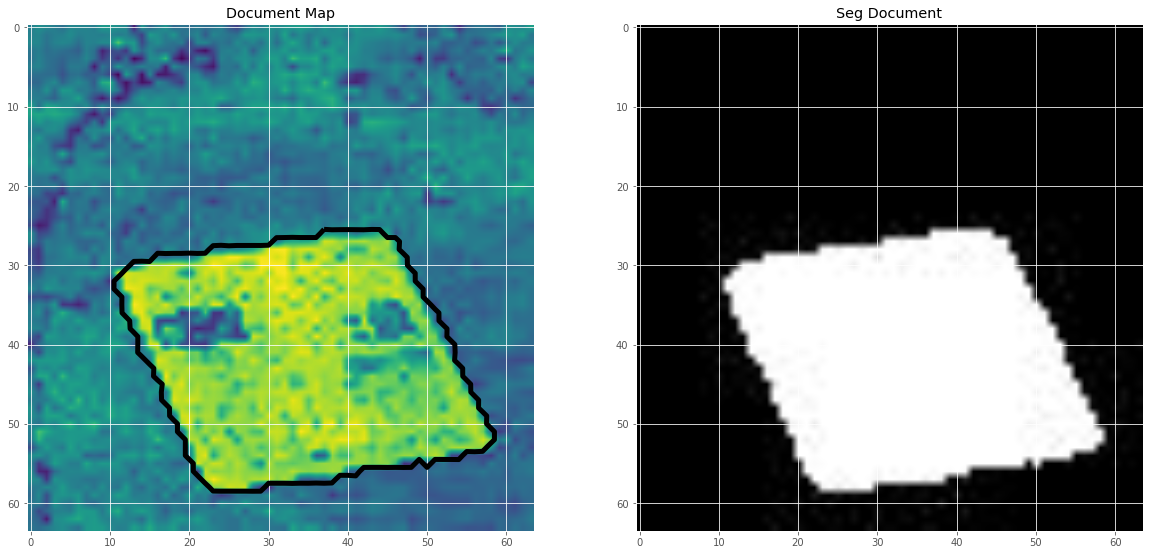

In [15]:
# Visualize any randome image along with the mask
ix = random.randint(0, len(X_train))
has_mask = y_train[ix].max() > 0 # salt indicator

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (20, 15))

ax1.imshow(X_train[ix, ..., 0], interpolation = 'bilinear')
if has_mask: # if salt
    # draw a boundary(contour) in the original image separating salt and non-salt areas
    ax1.contour(y_train[ix].squeeze(), colors = 'k', linewidths = 5, levels = [0.5])
ax1.set_title('Document Map')

ax2.imshow(y_train[ix].squeeze(), cmap = 'gray', interpolation = 'bilinear')
ax2.set_title('Seg Document')

In [19]:

def conv2d_block(input_tensor, n_filters, kernel_size = 3, batchnorm = True):
    """Function to add 2 convolutional layers with the parameters passed to it"""
    # first layer
    x = Conv2D(filters = n_filters, kernel_size = (kernel_size, kernel_size),\
              kernel_initializer = 'he_normal', padding = 'same')(input_tensor)
    if batchnorm:
        x = BatchNormalization()(x)
    x = Activation('relu')(x)
    
    # second layer
    x = Conv2D(filters = n_filters, kernel_size = (kernel_size, kernel_size),\
              kernel_initializer = 'he_normal', padding = 'same')(x)
    if batchnorm:
        x = BatchNormalization()(x)
    x = Activation('relu')(x)
    
    # Third layer
    x = Conv2D(filters = n_filters, kernel_size = (kernel_size, kernel_size),\
              kernel_initializer = 'he_normal', padding = 'same')(x)
    if batchnorm:
        x = BatchNormalization()(x)
    x = Activation('relu')(x)
    
    return x
  
def get_unet(input_img, n_filters = 16, dropout = 0.1, batchnorm = True):
    # Contracting Path
    c1 = conv2d_block(input_img, n_filters * 1, kernel_size = 3, batchnorm = batchnorm)
    p1 = MaxPooling2D((2, 2))(c1)
    p1 = Dropout(dropout)(p1)
    
    c2 = conv2d_block(p1, n_filters * 2, kernel_size = 3, batchnorm = batchnorm)
    p2 = MaxPooling2D((2, 2))(c2)
    p2 = Dropout(dropout)(p2)
    
    c3 = conv2d_block(p2, n_filters * 4, kernel_size = 3, batchnorm = batchnorm)
    p3 = MaxPooling2D((2, 2))(c3)
    p3 = Dropout(dropout)(p3)
    
    c4 = conv2d_block(p3, n_filters * 8, kernel_size = 3, batchnorm = batchnorm)
    p4 = MaxPooling2D((2, 2))(c4)
    p4 = Dropout(dropout)(p4)
    
    c5 = conv2d_block(p4, n_filters = n_filters * 16, kernel_size = 3, batchnorm = batchnorm)
    
    # Expansive Path
    u6 = Conv2DTranspose(n_filters * 8, (3, 3), strides = (2, 2), padding = 'same')(c5)
    u6 = concatenate([u6, c4])
    u6 = Dropout(dropout)(u6)
    c6 = conv2d_block(u6, n_filters * 8, kernel_size = 3, batchnorm = batchnorm)
    
    u7 = Conv2DTranspose(n_filters * 4, (3, 3), strides = (2, 2), padding = 'same')(c6)
    u7 = concatenate([u7, c3])
    u7 = Dropout(dropout)(u7)
    c7 = conv2d_block(u7, n_filters * 4, kernel_size = 3, batchnorm = batchnorm)
    
    u8 = Conv2DTranspose(n_filters * 2, (3, 3), strides = (2, 2), padding = 'same')(c7)
    u8 = concatenate([u8, c2])
    u8 = Dropout(dropout)(u8)
    c8 = conv2d_block(u8, n_filters * 2, kernel_size = 3, batchnorm = batchnorm)
    
    u9 = Conv2DTranspose(n_filters * 1, (3, 3), strides = (2, 2), padding = 'same')(c8)
    u9 = concatenate([u9, c1])
    u9 = Dropout(dropout)(u9)
    c9 = conv2d_block(u9, n_filters * 1, kernel_size = 3, batchnorm = batchnorm)
    
    outputs = Conv2D(1, (1, 1), activation='sigmoid')(c9)
    model = Model(inputs=[input_img], outputs=[outputs])
    return model

In [20]:
input_img = Input((im_height, im_width, 1), name='img')
model = get_unet(input_img, n_filters=16, dropout=0.05, batchnorm=True)
model.compile(optimizer=Adam(), loss="binary_crossentropy", metrics=["accuracy"])

In [21]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
img (InputLayer)                [(None, 64, 64, 1)]  0                                            
__________________________________________________________________________________________________
conv2d_1 (Conv2D)               (None, 64, 64, 16)   160         img[0][0]                        
__________________________________________________________________________________________________
batch_normalization (BatchNorma (None, 64, 64, 16)   64          conv2d_1[0][0]                   
__________________________________________________________________________________________________
activation (Activation)         (None, 64, 64, 16)   0           batch_normalization[0][0]        
______________________________________________________________________________________________

In [38]:
callbacks = [
    ReduceLROnPlateau(factor=0.1, patience=5, min_lr=0.00001, verbose=1),
    
]

In [39]:
results = model.fit(X_train, y_train, batch_size=32, epochs=100, callbacks=callbacks,\
                    validation_data=(X_valid, y_valid))

Epoch 1/100
13/13 [==============================] - 0s 38ms/step - loss: 0.0841 - accuracy: 0.8545 - val_loss: 0.1044 - val_accuracy: 0.8501
Epoch 2/100
13/13 [==============================] - 0s 33ms/step - loss: 0.0827 - accuracy: 0.8550 - val_loss: 0.1045 - val_accuracy: 0.8501
Epoch 3/100
13/13 [==============================] - 0s 33ms/step - loss: 0.0844 - accuracy: 0.8545 - val_loss: 0.1044 - val_accuracy: 0.8502
Epoch 4/100
13/13 [==============================] - 0s 33ms/step - loss: 0.0805 - accuracy: 0.8556 - val_loss: 0.1041 - val_accuracy: 0.8504
Epoch 5/100
13/13 [==============================] - 0s 35ms/step - loss: 0.0849 - accuracy: 0.8544 - val_loss: 0.1042 - val_accuracy: 0.8504
Epoch 6/100
13/13 [==============================] - 0s 34ms/step - loss: 0.0871 - accuracy: 0.8532 - val_loss: 0.1045 - val_accuracy: 0.8502
Epoch 7/100
13/13 [==============================] - 0s 32ms/step - loss: 0.0835 - accuracy: 0.8546 - val_loss: 0.1052 - val_accuracy: 0.8500
Epoch 

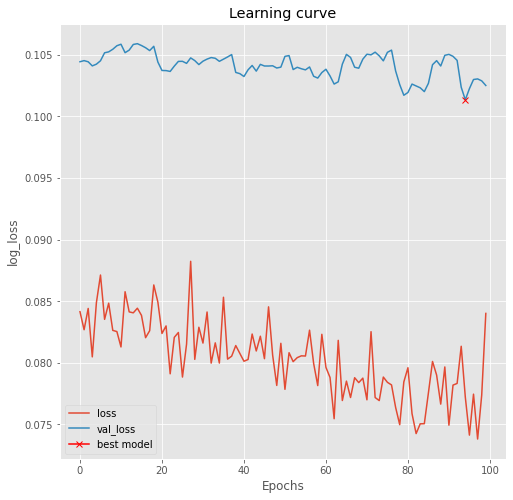

In [40]:
plt.figure(figsize=(8, 8))
plt.title("Learning curve")
plt.plot(results.history["loss"], label="loss")
plt.plot(results.history["val_loss"], label="val_loss")
plt.plot( np.argmin(results.history["val_loss"]), np.min(results.history["val_loss"]), marker="x", color="r", label="best model")
plt.xlabel("Epochs")
plt.ylabel("log_loss")
plt.legend();

In [41]:
# load the best model
model.load_weights('model-hair.h5')

In [42]:
model.evaluate(X_valid, y_valid, verbose=1)

4/4 [==============================] - 0s 9ms/step - loss: 0.1049 - accuracy: 0.8500


[0.10492884367704391, 0.8500195145606995]

In [43]:
preds_train = model.predict(X_train, verbose=1)
preds_val = model.predict(X_valid, verbose=1)

4/4 [==============================] - 0s 9ms/step


In [44]:
preds_train_t = (preds_train > 0.5).astype(np.uint8)
preds_val_t = (preds_val > 0.5).astype(np.uint8)

In [45]:
def plot_sample(X, y, preds, binary_preds, ix=None):
    """Function to plot the results"""
    if ix is None:
        ix = random.randint(0, len(X))

    has_mask = y[ix].max() > 0

    fig, ax = plt.subplots(1, 4, figsize=(20, 10))
    #ax[0].imshow(X[ix, ..., 0], cmap='seismic')
    ax[0].imshow(X[ix, ..., 0])
    #if has_mask:
        #ax[0].contour(y[ix].squeeze(), colors='k', levels=[0.5])
    ax[0].set_title('document Heatmap')

    ax[1].imshow(y[ix].squeeze())
    ax[1].set_title('Document')

    ax[2].imshow(preds[ix].squeeze(), vmin=0, vmax=1)
    if has_mask:
        ax[2].contour(y[ix].squeeze(), colors='k', levels=[0.5])
    ax[2].set_title('document detected')
    
    ax[3].imshow(binary_preds[ix].squeeze(), vmin=0, vmax=1)
    if has_mask:
        ax[3].contour(y[ix].squeeze(), colors='k', levels=[0.5])
    ax[3].set_title('Document Predicted binary');

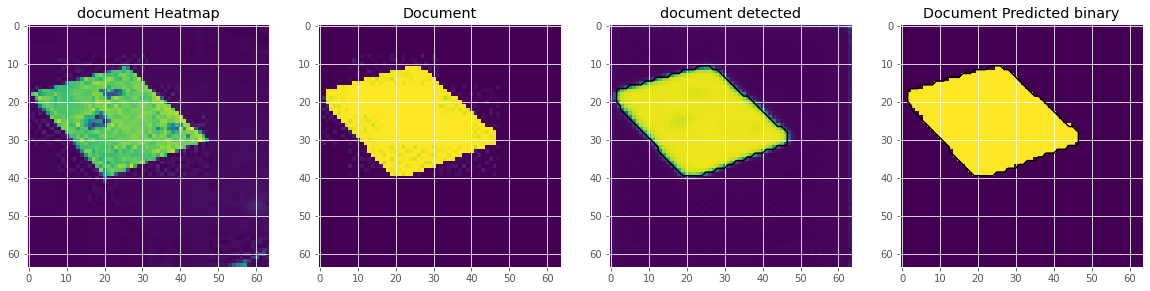

In [47]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

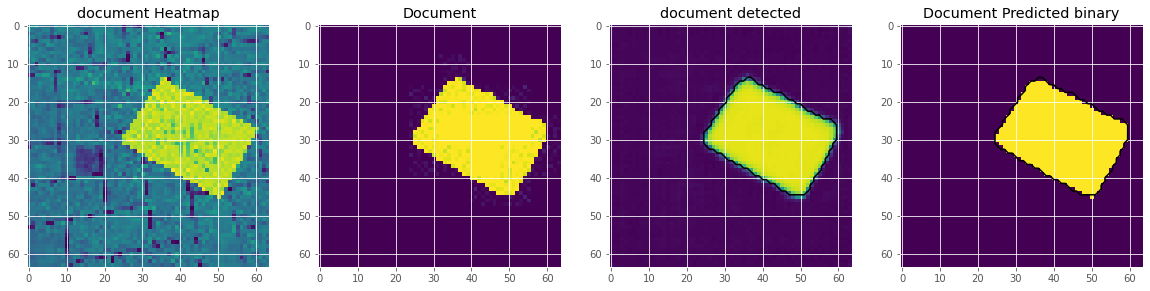

In [48]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

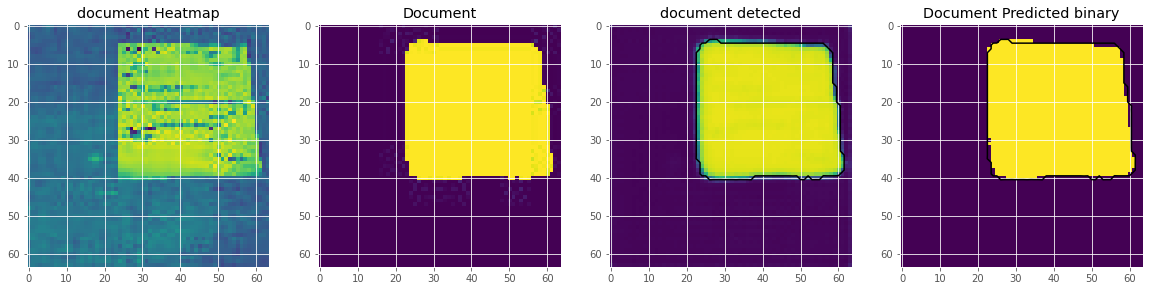

In [49]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

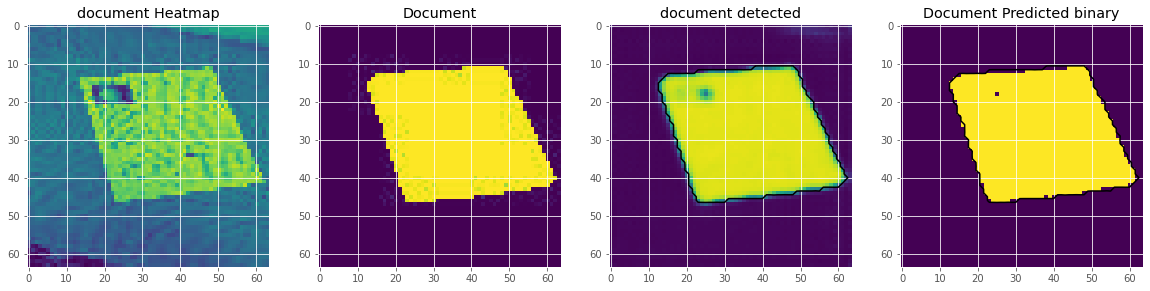

In [50]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

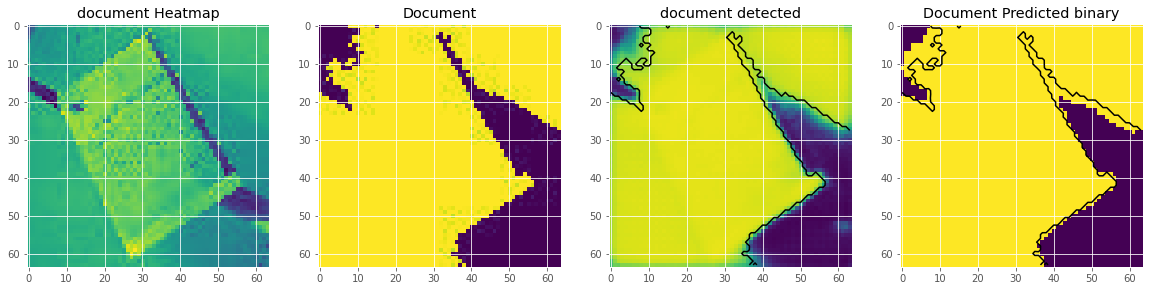

In [51]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

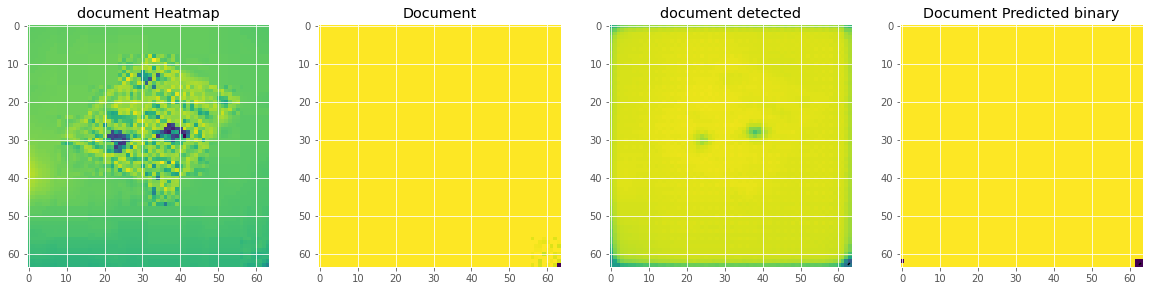

In [52]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

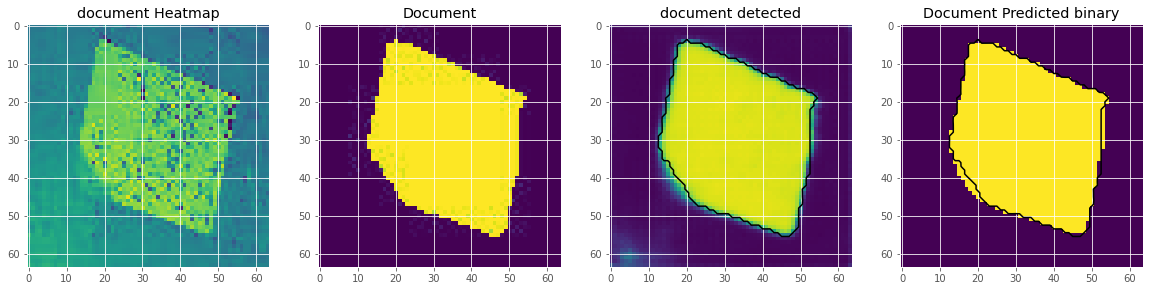

In [53]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

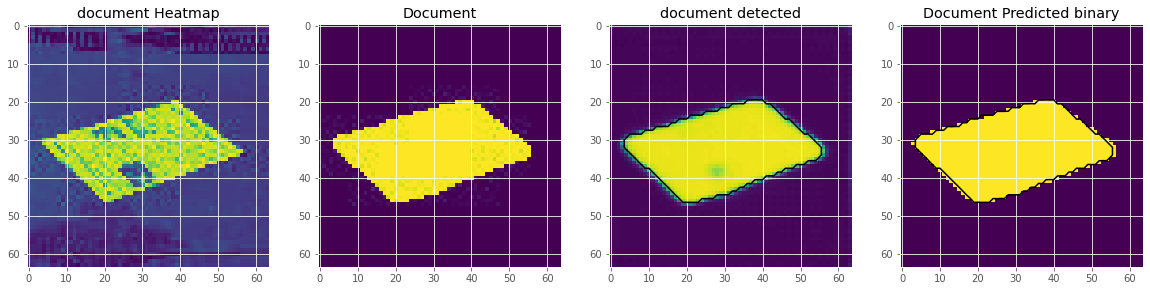

In [54]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

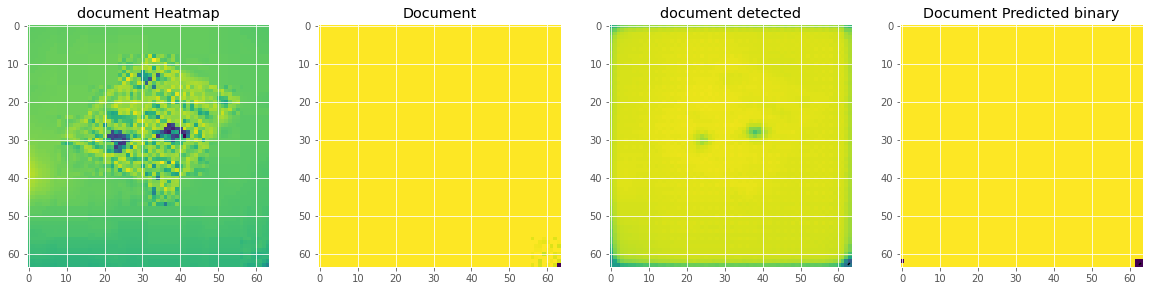

In [55]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

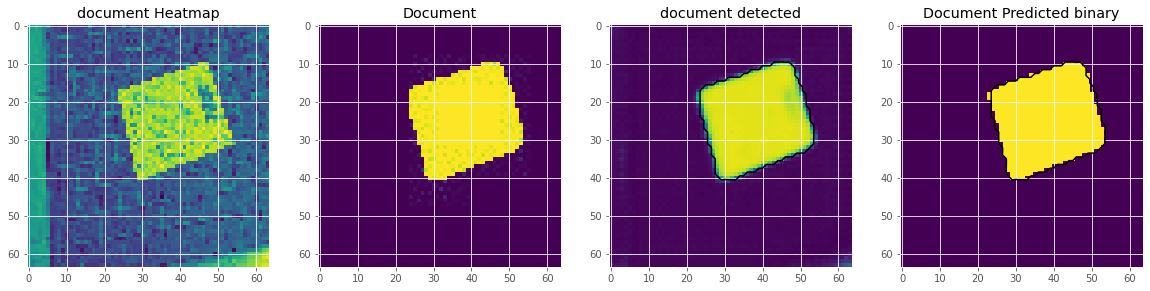

In [56]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

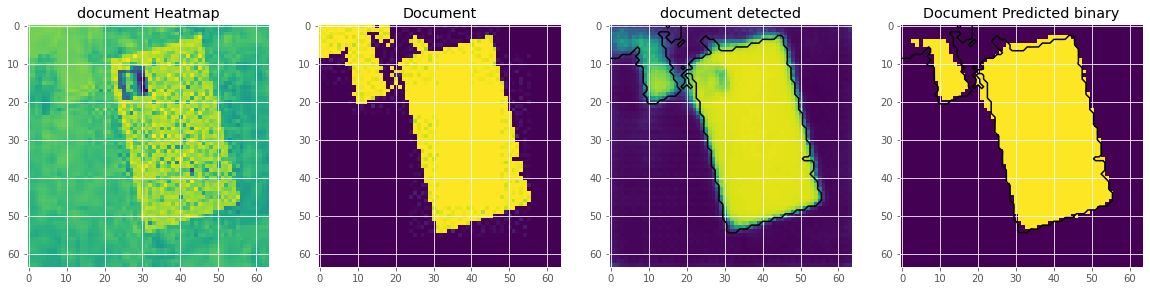

In [57]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

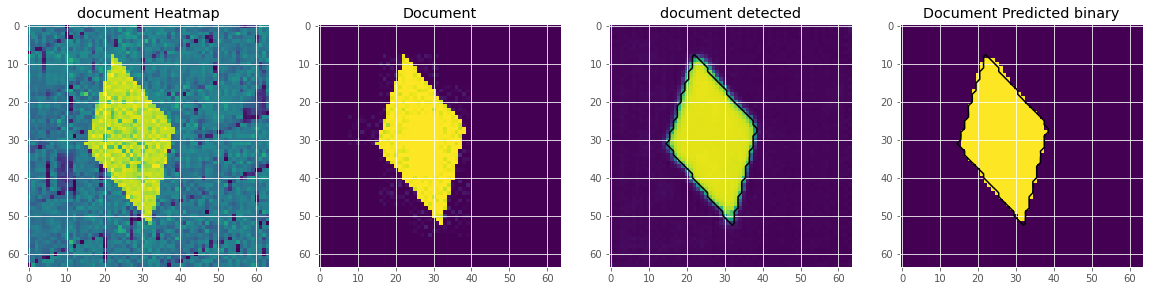

In [58]:
# Check if valid data looks all right
plot_sample(X_valid, y_valid, preds_val, preds_val_t, ix=4)

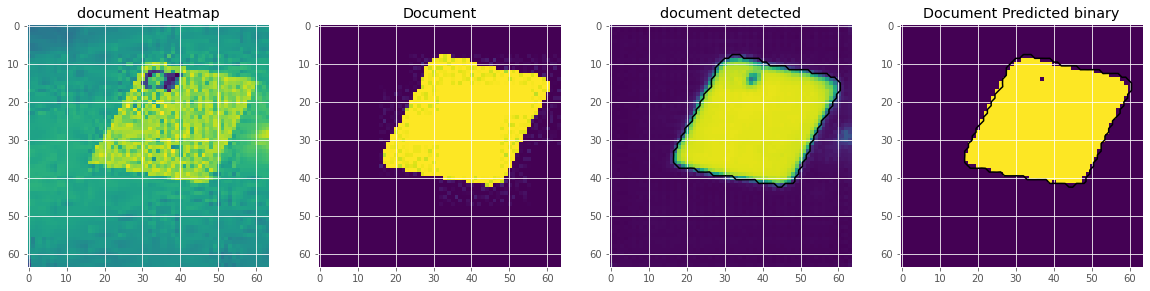

In [59]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

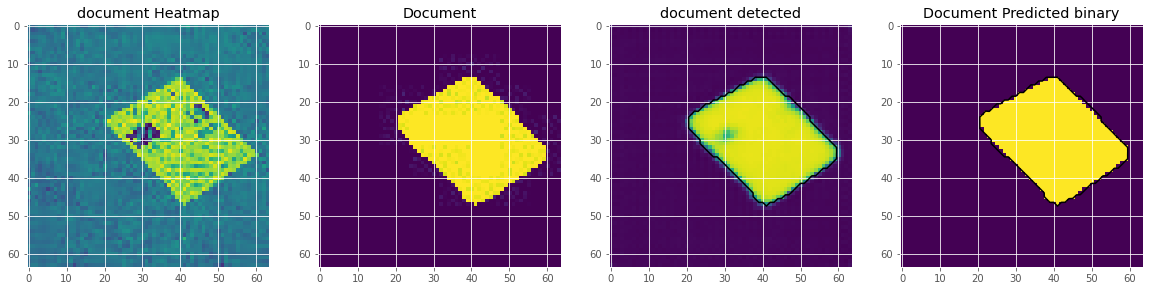

In [60]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

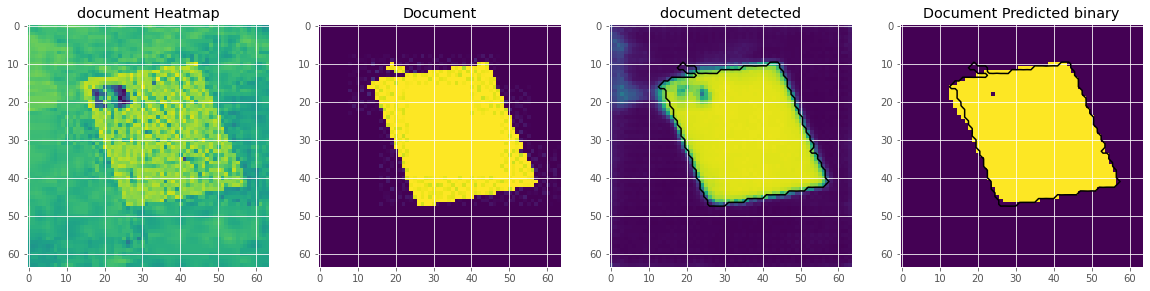

In [61]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

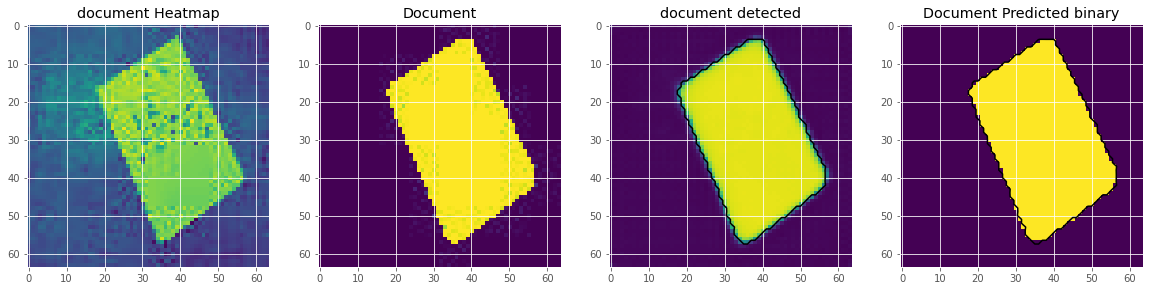

In [62]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

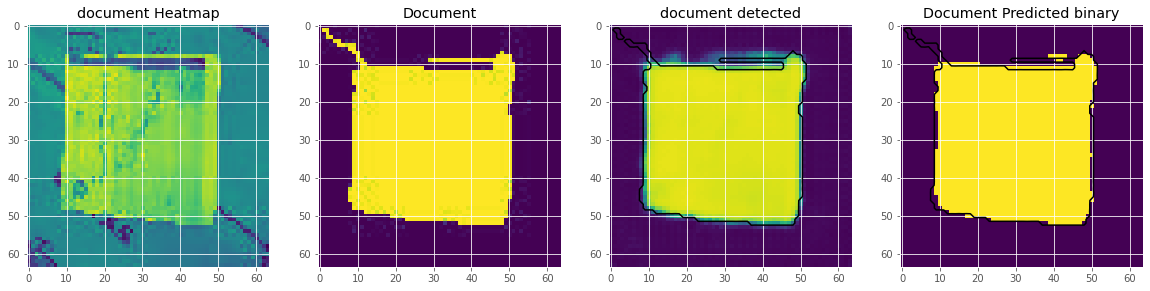

In [63]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

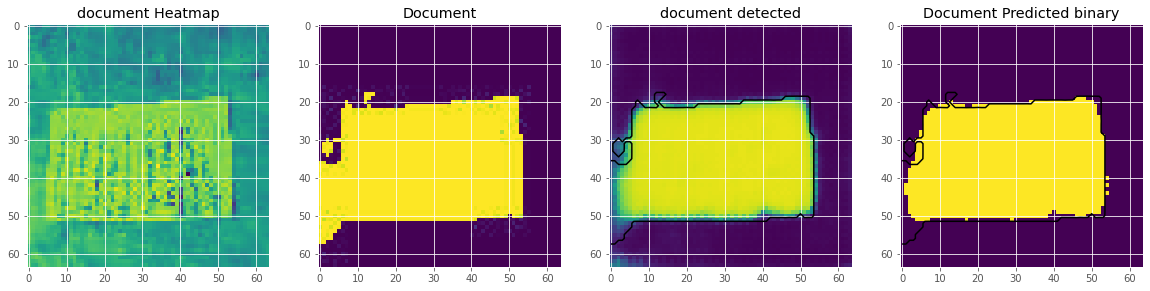

In [64]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

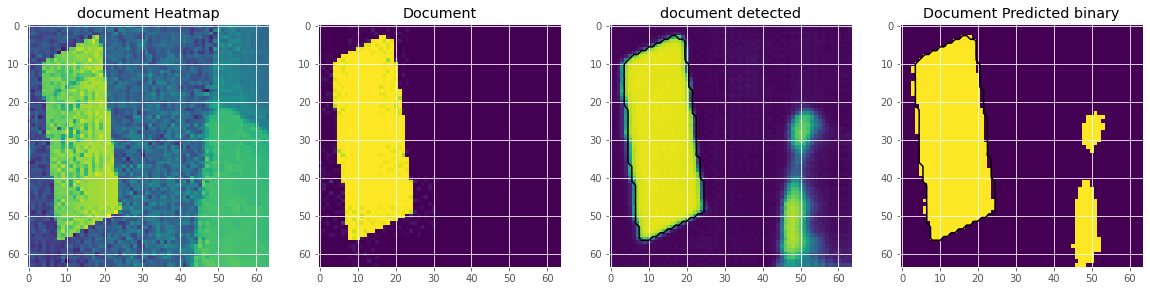

In [65]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

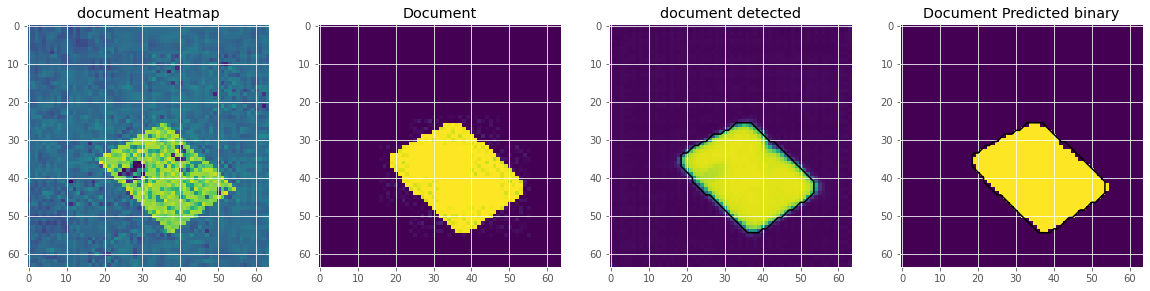

In [66]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

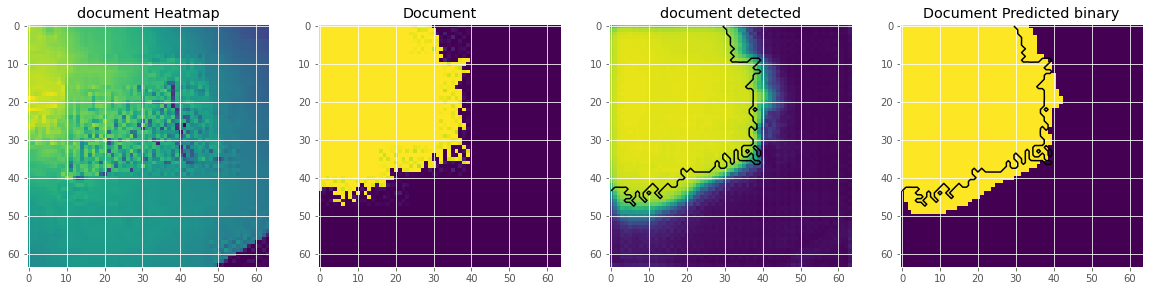

In [67]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

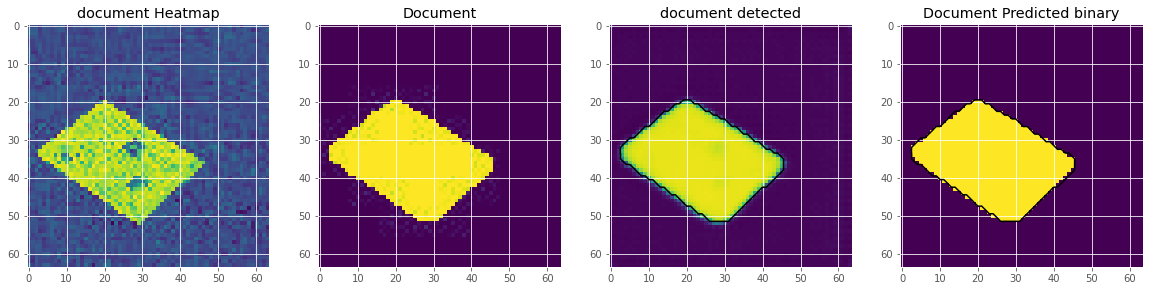

In [68]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

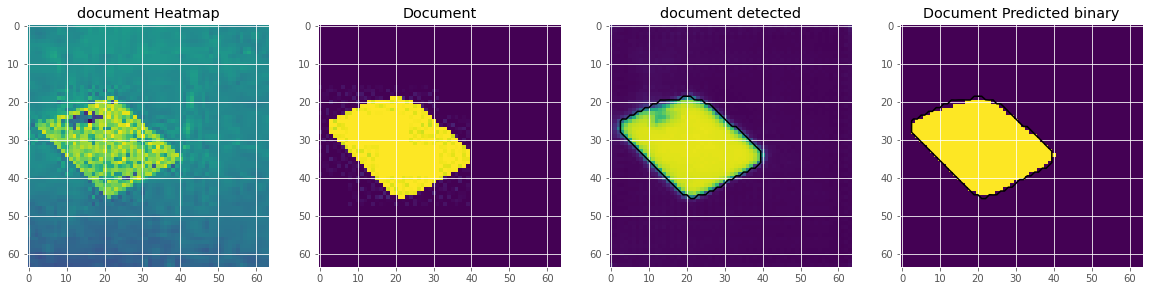

In [69]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

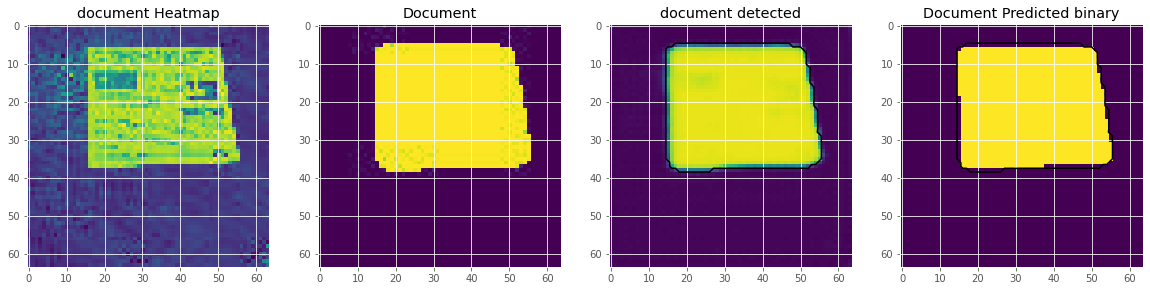

In [70]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

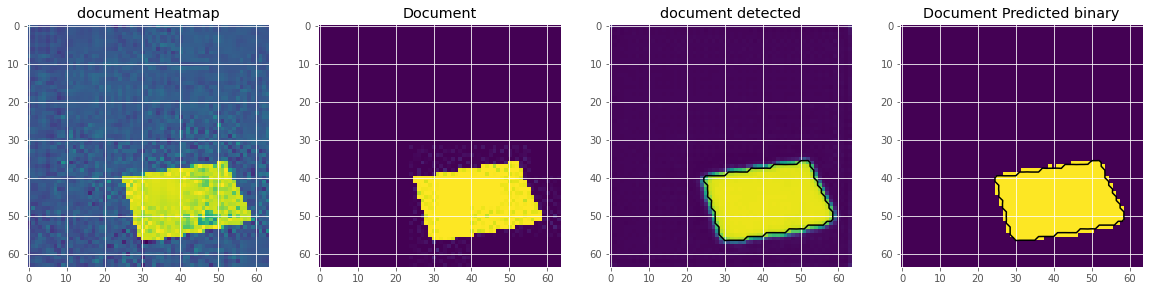

In [71]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

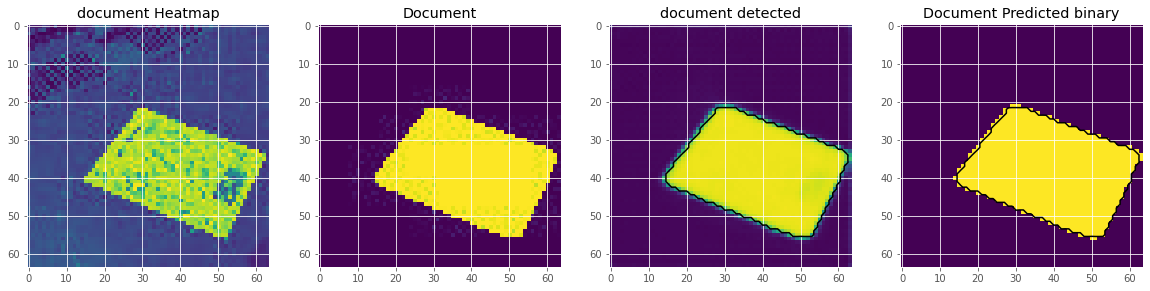

In [72]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)